In [1]:
# unzip files
!unzip -q hw6.zip
%cd hw6

# # after restarting the kernel, make sure the files are still available
# %cd /content/hw5
!ls

/content/hw6
base_classification.py	  overfit.png
classification.py	  requirements.txt
gpt3_boolq_evaluation.py  rkhandpur_hw6_colab_2.ipynb
hw6.md			  rkhandpur_hw6_colab.ipynb
openai_gpt-boolq.py	  rkhandpur_hw6_scrap_local.ipynb


In [2]:
# # install requirements
# !pip install -q -r requirements.txt # this errored so tried directly below
# !pip install -q datasets==2.17.1 evaluate==0.4.1 matplotlib==3.8.3 openai==1.12.0 regex==2023.12.25 transformers==4.38.1 scikit-learn
!pip install -q -U "numpy>=2" "transformers>=4.46,<5" "datasets>=3" "evaluate>=0.4.3" "matplotlib>=3.9" scikit-learn
# # %cd /content/hw6        # your folder
import numpy, torch, transformers, datasets, evaluate
print(numpy.__version__, torch.__version__, transformers.__version__, datasets.__version__)
print("CUDA:", torch.cuda.is_available())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
2.4.6 2.14.1+cu130 4.57.6 5.0.1
CUDA: True


In [3]:
!USE_TF=0 python classification.py --type full --model roberta-base --lr 1e-4 --num_epochs 7 --batch_size 32 --device cuda 2>&1 | tee roberta_full.log

Specified arguments: Namespace(small_subset=False, num_epochs=7, lr=0.0001, batch_size=32, device='cuda', model='roberta-base', type='full', prefix_length=128)
Loading the dataset ...
Generating validation split: 100%|██████████| 3270/3270 [00:00<00:00, 685186.30 examples/s]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Slicing the data...
Size of the loaded dataset:
 - train: 8000
 - dev: 3270
 - test: 1427
Loading the tokenizer...
Loding the data into DS...
 >>>>>>>> Initializing the data loaders ... 
Loading the model ...
Moving model to device ...cuda
 >>>>>>>>  Starting training ... 
 >>>>>>>>  Initializing optimizer
Epoch 1 training:
250it [00:19, 13.06it/s]
 ===> Epoch 1
 - Average training metrics: accuracy={'accuracy': 0.61825}
 - Average validation me

 - Average DEV metrics: accuracy={'accuracy': 0.6217125382262997}
 - Average TEST metrics: accuracy={'accuracy': 0.6355991590749824}


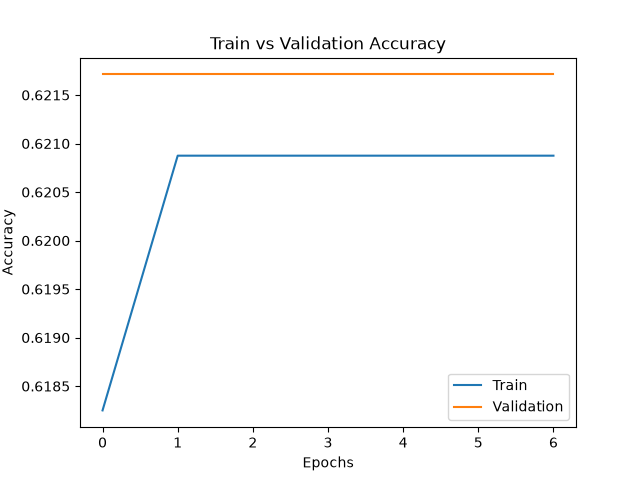

In [4]:
!grep -E "Average (DEV|TEST) metrics" roberta_full.log | tail -2
from IPython.display import Image
Image("roberta-base_full.png")

# Head tuning

In [7]:
from google.colab import files
files.upload()

Saving classification_lora.py to classification_lora.py


{'classification_lora.py': b'import torch\nfrom torch.utils.data import DataLoader\nfrom transformers import AutoTokenizer\nfrom torch.utils.data import DataLoader\nfrom datasets import load_dataset\nfrom tqdm import tqdm\nimport evaluate as evaluate\nfrom transformers import get_scheduler\nfrom transformers import AutoModelForSequenceClassification\nimport argparse\nimport subprocess\nimport matplotlib.pyplot as plt\nfrom peft import LoraConfig, TaskType, get_peft_model\n\ndef print_gpu_memory():\n    """\n    Print the amount of GPU memory used by the current process\n    This is useful for debugging memory issues on the GPU\n    """\n    # check if gpu is available\n    if torch.cuda.is_available():\n        print("torch.cuda.memory_allocated: %fGB" % (torch.cuda.memory_allocated(0) / 1024 / 1024 / 1024))\n        print("torch.cuda.memory_reserved: %fGB" % (torch.cuda.memory_reserved(0) / 1024 / 1024 / 1024))\n        print("torch.cuda.max_memory_reserved: %fGB" % (torch.cuda.max_me

In [10]:
!pwd
!ls -la /content/ /content/hw6/ | grep -i classif
!grep -n "NotImplementedError" /content/hw6/classification.py

/content/hw6
-rw-r--r-- 1 root root 13524 Nov  9 03:27 base_classification.py
-rw-r--r-- 1 root root 20687 Nov  9 03:57 classification (1).py
-rw-r--r-- 1 root root 20687 Nov  9 03:59 classification (2).py
-rw-r--r-- 1 root root 20269 Nov  9 03:30 classification.py
35:            # raise NotImplementedError("You need to implement the forward function for the full model")
53:            raise NotImplementedError("You need to implement the forward function for the head-tuned model")
61:            raise NotImplementedError("You need to implement the forward function for the prefix-tuned model")
183:        # raise NotImplementedError("You need to implement the evaluation function")
236:        raise NotImplementedError("You need to implement the optimizer for head-tuned model")
247:        raise NotImplementedError("You need to implement the optimizer for prefix-tuned model")
303:            # raise NotImplementedError("You need to implement this function")


In [2]:
%cd /content/hw6
!mv "classification (1).py" classification.py
# !rm "classification (1).py"
!grep -n "NotImplementedError" classification.py

[Errno 2] No such file or directory: '/content/hw6'
/content
mv: cannot stat 'classification (1).py': No such file or directory
35:            # raise NotImplementedError("You need to implement the forward function for the full model")
53:            # raise NotImplementedError("You need to implement the forward function for the head-tuned model")
66:            raise NotImplementedError("You need to implement the forward function for the prefix-tuned model")
188:        # raise NotImplementedError("You need to implement the evaluation function")
241:        # raise NotImplementedError("You need to implement the optimizer for head-tuned model")
255:        # raise NotImplementedError("You need to implement the optimizer for prefix-tuned model")
313:            # raise NotImplementedError("You need to implement this function")


In [13]:
!USE_TF=0 python classification.py --type head --model roberta-base --lr 1e-4 --num_epochs 7 --batch_size 32 --device cuda 2>&1 | tee roberta_head.log
!grep -E "Average (DEV|TEST) metrics" roberta_head.log | tail -2

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Specified arguments: Namespace(small_subset=False, num_epochs=7, lr=0.0001, batch_size=32, device='cuda', model='roberta-base', type='head', prefix_length=128)
Loading the dataset ...
Slicing the data...
Size of the loaded dataset:
 - train: 8000
 - dev: 3270
 - test: 1427
Loading the tokenizer...
Loding the data into DS...
 >>>>>>>> Initializing the data loaders ... 
Loading the model ...
Moving model to device ...cuda
 >>>>>>>>  Starting training ... 
 >>>>>>>>  Initializing optimizer
Epoch 1 training:
0it [00:00, ?it/s]/content/hw6/classification.py:344: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer

In [ ]:
# PREFIX TUNING

In [6]:
!USE_TF=0 python classification.py --type prefix --model roberta-base --prefix_length 128 --lr 1e-4 --num_epochs 7 --batch_size 32 --device cuda 2>&1 | tee roberta_prefix.log

Specified arguments: Namespace(small_subset=False, num_epochs=7, lr=0.0001, batch_size=32, device='cuda', model='roberta-base', type='prefix', prefix_length=128)
Loading the dataset ...
Generating validation split: 100%|██████████| 3270/3270 [00:00<00:00, 322161.32 examples/s]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Slicing the data...
Size of the loaded dataset:
 - train: 8000
 - dev: 3270
 - test: 1427
Loading the tokenizer...
Loding the data into DS...
 >>>>>>>> Initializing the data loaders ... 
Loading the model ...
Moving model to device ...cuda
 >>>>>>>>  Starting training ... 
 >>>>>>>>  Initializing optimizer
Epoch 1 training:
0it [00:00, ?it/s]/content/hw6/classification.py:361: UserWarning: Detected call of `lr_scheduler.step()` before `optimiz

# Extra Credit; memory barcharts

In [3]:
import os
os.environ["USE_TF"] = "0"
import gc, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from torch.profiler import profile, record_function, ProfilerActivity
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, set_seed
import importlib, classification as clf
importlib.reload(clf)

MODEL, DEVICE, BATCH, MAX_LEN, LR = "roberta-base", "cuda", 32, 128, 1e-4
clf.prefix_length = 128          # CustomModelforSequenceClassification.__init__ reads this global
FREEZE = True                    # True: only the tuned params get gradients (see note)

set_seed(42)
raw = load_dataset("google/boolq")["train"][:BATCH]
tok = AutoTokenizer.from_pretrained(MODEL, use_fast=False)
ds = clf.BoolQADataset(raw["passage"], raw["question"], raw["answer"], tok, MAX_LEN)
batch = next(iter(DataLoader(ds, batch_size=BATCH)))
input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)
labels = batch["labels"].to(DEVICE)
loss_fn = torch.nn.CrossEntropyLoss()

def tuned_params(model, t):
    if t == "full":   return list(model.parameters())
    if t == "head":   return list(model.classifier.parameters())
    if t == "prefix": return [model.prefix] + list(model.classifier.parameters())

def event_mem(prof, name):
    """Total (incl. children) device memory attributed to a record_function block, in bytes."""
    for e in prof.key_averages():
        if e.key == name:
            return getattr(e, "device_memory_usage", None) or getattr(e, "cuda_memory_usage", 0)
    return 0

def print_table(prof):
    try:
        print(prof.key_averages().table(sort_by="device_memory_usage", row_limit=4))
    except Exception:
        print(prof.key_averages().table(sort_by="cuda_memory_usage", row_limit=4))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.69M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/1.26M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9427 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3270 [00:00<?, ? examples/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [4]:
rows = []
for t in ["full", "head", "prefix"]:
    print(f"\n{'=' * 25} {t} {'=' * 25}")
    model = clf.CustomModelforSequenceClassification(MODEL, num_labels=2, type=t).to(DEVICE)
    model.train()
    params = tuned_params(model, t)
    if FREEZE:
        for p in model.parameters(): p.requires_grad_(False)
        for p in params:             p.requires_grad_(True)
    optimizer = torch.optim.AdamW(params, lr=LR)

    with torch.no_grad():   # warm-up so one-time CUDA/cuBLAS init isn't counted
        model(input_ids=input_ids, attention_mask=attention_mask)
    torch.cuda.synchronize()

    # ---- forward ----
    torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
                 profile_memory=True, record_shapes=True) as prof:
        with record_function("forward"):
            output = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = loss_fn(output["logits"], labels)
    fwd_prof, fwd_peak = event_mem(prof, "forward"), torch.cuda.max_memory_allocated() - base
    print_table(prof)

    # ---- backward (+ optimizer step, as in the tutorial) ----
    torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
                 profile_memory=True, record_shapes=True) as prof:
        with record_function("backward"):
            loss.backward()
            optimizer.step()
    bwd_prof, bwd_peak = event_mem(prof, "backward"), torch.cuda.max_memory_allocated() - base
    print_table(prof)

    rows.append(dict(method=t, tuned_params=sum(p.numel() for p in params),
                     forward_MB=fwd_prof / 2**20, backward_MB=bwd_prof / 2**20,
                     forward_peak_MB=fwd_peak / 2**20, backward_peak_MB=bwd_peak / 2**20))

    del model, optimizer, output, loss, params, prof
    gc.collect(); torch.cuda.empty_cache()

mem = pd.DataFrame(rows)
mem.to_csv("memory_profile.csv", index=False)
display(mem.round(1))


========================= full =========================


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                forward        11.56%      13.949ms        99.98%     120.667ms     120.667ms       0.000us         0.00%      55.997ms      55.997ms         192 B          -4 B       2.34 GB    -640.82 M

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                           aten::linear         1.50%     730.463us         9.88%       4.796ms      64.810us       0.000us         0.00%      42.036ms     568.053us           0 B           0 B       1.27 GB           0 

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                forward         6.94%       6.556ms        32.06%      30.287ms      30.287ms       0.000us         0.00%      91.240ms      91.240ms         192 B          -4 B       3.00 GB      -2.96 G

,method,tuned_params,forward_MB,backward_MB,forward_peak_MB,backward_peak_MB
0,full,124745474,2397.0,-904.6,2420.9,98.0
1,head,1538,0.1,-0.1,134.0,0.0
2,prefix,99842,3068.2,-3067.0,3320.2,185.8


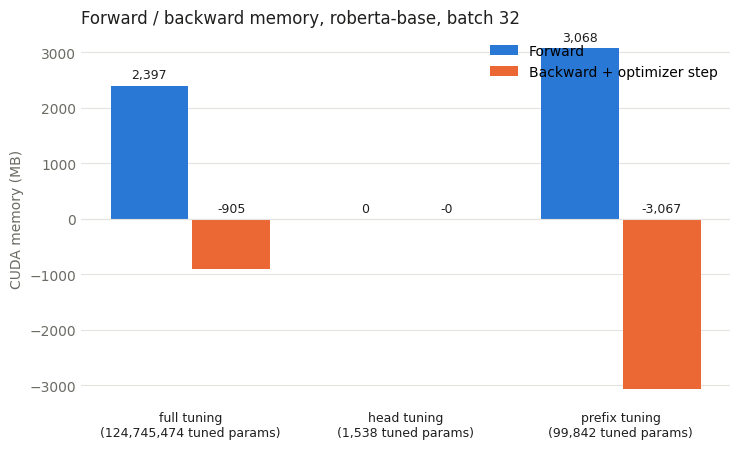

In [5]:
x, w, gap = np.arange(len(mem)), 0.36, 0.01
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3de"

fig, ax = plt.subplots(figsize=(7.5, 4.6))
b1 = ax.bar(x - w/2 - gap, mem["forward_MB"],  w, color="#2a78d6", label="Forward")
b2 = ax.bar(x + w/2 + gap, mem["backward_MB"], w, color="#eb6834", label="Backward + optimizer step")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:,.0f}", (bar.get_x() + bar.get_width()/2, max(h, 0)), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK)

ax.set_xticks(x, [f"{m} tuning\n({n:,} tuned params)" for m, n in zip(mem["method"], mem["tuned_params"])],
              fontsize=9, color=INK)
ax.set_ylabel("CUDA memory (MB)", color=MUTED)
ax.set_title(f"Forward / backward memory, {MODEL}, batch {BATCH}", loc="left", color=INK)
ax.axhline(0, color=GRID, linewidth=0.8)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left", "bottom"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", colors=MUTED, length=0); ax.tick_params(axis="x", length=0)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig("memory_profile.png", dpi=150); plt.show()

# LoRA fine-tuning Extra Credit

In [9]:
!pip uninstall -y torchao
!USE_TF=0 python classification_lora.py --model roberta-base --lr 1e-4 --num_epochs 7 --batch_size 32 --device cuda 2>&1 | tee roberta_lora.log
!grep -E "trainable params|Average (DEV|TEST) metrics" roberta_lora.log

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Specified arguments: Namespace(small_subset=False, num_epochs=7, lr=0.0001, batch_size=32, device='cuda', model='roberta-base', lora_r=8, lora_alpha=16, lora_dropout=0.1)
Loading the dataset ...
Slicing the data...
Size of the loaded dataset:
 - train: 8000
 - dev: 3270
 - test: 1427
Loading the tokenizer...
Loding the data into DS...
 >>>>>>>> Initializing the data loaders ... 
Loading the model ...
trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
Moving model to device ...cuda
 >>>>>>>>  Sta